# Mixer spur analysis in xcvr

This notebook walks through the spur tools, from one mixer at one frequency up to a full
receiver chain. Each plot is explained where it appears.

| Section | Question it answers | Main call |
|---|---|---|
| 1. Spur table | What does the datasheet say each product does? | `plot_table` |
| 2. A receiver | The system used throughout | `System`, `MixerConstant` |
| 3. One operating point | Which spurs land in my output band *right now*? | `mixer.spurs`, `plot_spectrum` |
| 4. Swept input | Across my whole band, where is it clean? | `System.spur_sweeps`, `plot_spur_sweep` |
| 5. Classic spur chart | The textbook view, with the in/out "box" | `plot_spur_chart` |
| 6. LO planning | Which LO frequencies work, and what filter do I need? | `xcvr.loplan` |
| 7. Spectrum sweep | Absolute spur power (dBm) at any node of the chain | `System.trace_tones` |

> **The bundled spur table is illustrative only.** Replace `SpurTable.default()` with your
> mixer's datasheet table (`SpurTable.from_csv("my_mixer.csv")`) before drawing conclusions.

**Frequency plan used throughout.** A C-band receiver for the **6 GHz band** (5.925–7.125 GHz,
the upper C-band spectrum used by 5G NR-U and Wi-Fi 6E) down-converted to an **L-band IF**
(0.925–2.125 GHz) with a **5.0 GHz LO**, and the matching up-converter in section 6. The signal is a
**100 MHz-wide** carrier (a 5G NR channel width) that can sit anywhere in the band.

**Conventions.** Frequencies are Hz (or pint quantities). A mixer's output contains
`|m·IN ± n·LO|` for integers m, n. Spur levels are in **dBc: dB below the desired product**.

In [ ]:
import warnings
import numpy as np
import skrf
import xarray as xr
import matplotlib.pyplot as plt
from xrench.units import ureg

from xcvr import (
    System,
    SpurTable,
    ToneSource,
    plot_spectrum_sweep,
    plot_spur_chart,
    plot_spur_sweep,
)
from xcvr.devices import Constant, MixerConstant
from xcvr.loplan import (
    Converter,
    analyze,
    best_los,
    filter_report,
    plot_filter_mask,
    plot_lo_sweep,
    plot_spur_map,
    sweep_lo,
)
from xcvr.spurs import plot_spectrum, plot_table, spur_free_ranges
from xcvr.xcvr import Device

warnings.filterwarnings("ignore", category=RuntimeWarning)  # skrf log10(0) noise from ideal devices
plt.rcParams["figure.dpi"] = 80

## 1. The spur table

A datasheet gives, for each product `m·IN ± n·LO`, how far below the desired output it sits.
**Rows are n (LO harmonic), columns are m (input harmonic).** The (1, 1) entry is the desired
product, so it is 0 dBc.

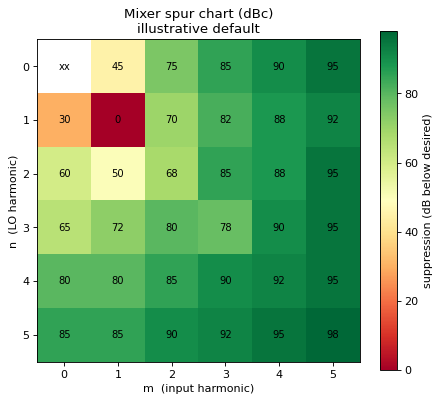

In [ ]:
table = SpurTable.default()  # ILLUSTRATIVE. Use SpurTable.from_csv("my_mixer.csv") for real data
plot_table(table);

**Reading the heatmap.** Green means well suppressed (a large number of dB below the desired
signal), red means strong. Column `m = 0` holds the pure LO harmonics (LO leakage, 30 dBc at
n = 1) and row `n = 0` holds input feedthrough and harmonics (45 dBc at m = 1). Products beyond
the table, or marked `xx`, are assumed to sit at `floor_dbc` (100 dBc by default).

You can build a table directly from a datasheet, or from a CSV with no header (row *i* is n = *i*,
column *j* is m = *j*; blank, `xx` or `nan` means unspecified).

## 2. A receiver to analyse

A downconverter: LNA → mixer (LO 5.0 GHz, below the RF, so output = |IN − LO|) → IF amp. The input
band is 5.925–7.125 GHz, so the L-band IF is 0.925–2.125 GHz.

Giving the mixer a `spur_table` is what enables spur analysis. Mixers without one are treated as
ideal (desired product only).

In [ ]:
fgrid = np.linspace(5.925e9, 7.125e9, 61)  # 6 GHz band, 20 MHz steps
freq = xr.DataArray(fgrid * ureg.Hz, dims=("frequency",), coords={"frequency": fgrid})

lna = Constant("LNA", "Generic", "LNA", frequency=freq, gain=20 * ureg.dB, nf=2 * ureg.dB)
mixer = MixerConstant(
    "MX1",
    "Generic",
    "MIXER",
    frequency=freq,
    gain=-7 * ureg.dB,
    nf=7 * ureg.dB,
    lo_freq=5.0 * ureg.GHz,
    sideband="low",  # "low": output = |IN - LO|   ("high": IN + LO)
    spur_table=table,  # <- enables spur analysis
)
ifa = Constant("IFA", "Generic", "IFA", frequency=freq, gain=15 * ureg.dB, nf=3 * ureg.dB)
rx = System("RX", "Generic", "001", [lna, mixer, ifa])

## 3. One operating point

`mixer.spurs()` lists every product for one input frequency. Here a 100 MHz-wide carrier sits at
6.667 GHz, so the desired output is at 1.667 GHz. For a modulated signal, an `m·IN` product is `m` times wider, so a spur can overlap
the output band even when its centre frequency is elsewhere.

In [ ]:
spurs = mixer.spurs(6.667 * ureg.GHz, signal_bw=100 * ureg.MHz, max_order=9)

print("In-band spurs (100 MHz signal at 6.667 GHz, 100 MHz output band):")
for s in spurs:
    if s.in_band and not s.is_desired:
        print(
            f"  {s.label:<14} {-s.eff_dbc:7.1f} dBc   ({s.overlap_frac:.0%} of its power inside the band)"
        )

In-band spurs (100 MHz signal at 6.667 GHz, 100 MHz output band):
  |2IN - 3LO|      -83.0 dBc   (50% of its power inside the band)
  |4IN - 5LO|     -101.0 dBc   (25% of its power inside the band)


`eff_dbc` is the suppression of the power that actually lands in your band: a spur that only half
overlaps the band counts as 3 dB better than its table value. Use it rather than the raw table
level when judging a modulated signal.

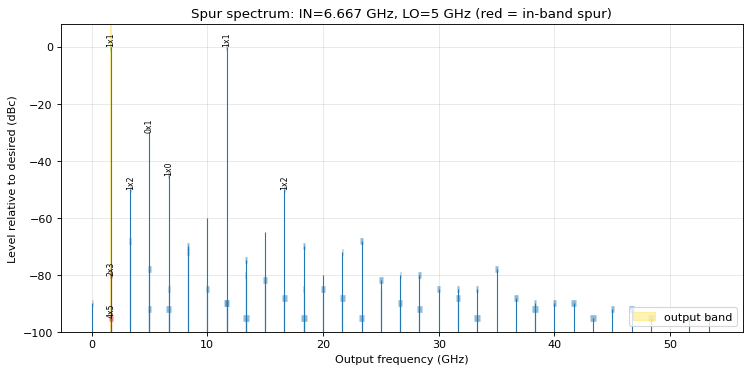

In [ ]:
plot_spectrum(
    spurs, 6.667 * ureg.GHz, 5.0 * ureg.GHz, out_center=1.667 * ureg.GHz, out_bw=100 * ureg.MHz
);

**Reading the spur spectrum.** The x-axis is *output* frequency, the y-axis is level relative to
the desired product. Each vertical line is a product's centre frequency; the thick horizontal bar
shows how wide it is for a modulated signal. The **gold band is your output band**.

* **Green**: the desired product (0 dBc).
* **Red**: spurs whose band overlaps the output band. These cannot be filtered out afterwards.
* **Blue**: spurs elsewhere. A filter can remove these, so they only matter for filter design.

Labels are `mxn` (m input harmonics, n LO harmonics). Only the desired, in-band, and strong
(< 60 dBc) spurs are labelled.

The full spectrum is dominated by products far from the band, so zoom in on the output band to see
the ones that matter. `plot_spectrum` returns the axes, so you can set the limits yourself:

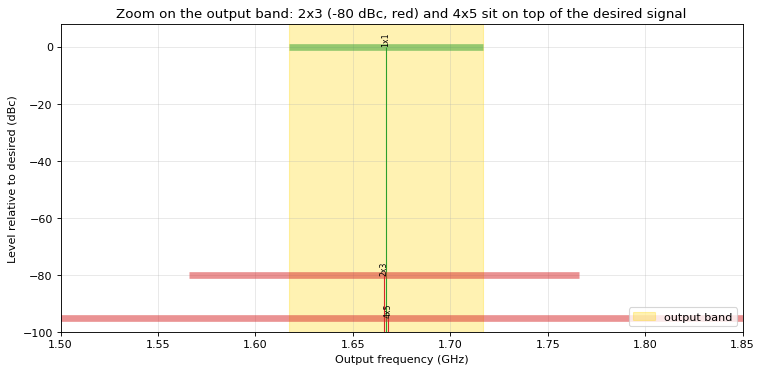

In [ ]:
ax = plot_spectrum(
    spurs, 6.667 * ureg.GHz, 5.0 * ureg.GHz, out_center=1.667 * ureg.GHz, out_bw=100 * ureg.MHz
)
ax.set_xlim(1.5, 1.85)  # the axis is in GHz here
ax.set_title(
    "Zoom on the output band: 2x3 (-80 dBc, red) and 4x5 sit on top of the desired signal"
);

Now the red lines are visible: the `2×3` and `4×5` products land on the desired signal at this
input frequency. Their bars are drawn wider than the desired product's because an `m·IN` product is
`m` times as wide as the signal. This is why a CW-only check would call this point clean.

## 4. Sweeping the input across the band

A single point can look clean while a spur crosses your band a few MHz away.
`System.spur_sweeps` sweeps each mixer over the carriers that actually reach its input and returns
one `xarray.Dataset` per mixer. `spec_dbc` is the suppression you require.

In [80]:
sweeps = rx.spur_sweeps(signal_bw=100 * ureg.MHz, max_order=9, spec_dbc=85)
sw = sweeps["MX1"]

print("Input ranges where every in-band spur meets -85 dBc:")
for lo, hi in spur_free_ranges(sw):
    print(f"  {lo / 1e9:.4f} - {hi / 1e9:.4f} GHz")

Input ranges where every in-band spur meets -85 dBc:
  5.9250 - 6.6162 GHz
  6.7170 - 7.1250 GHz


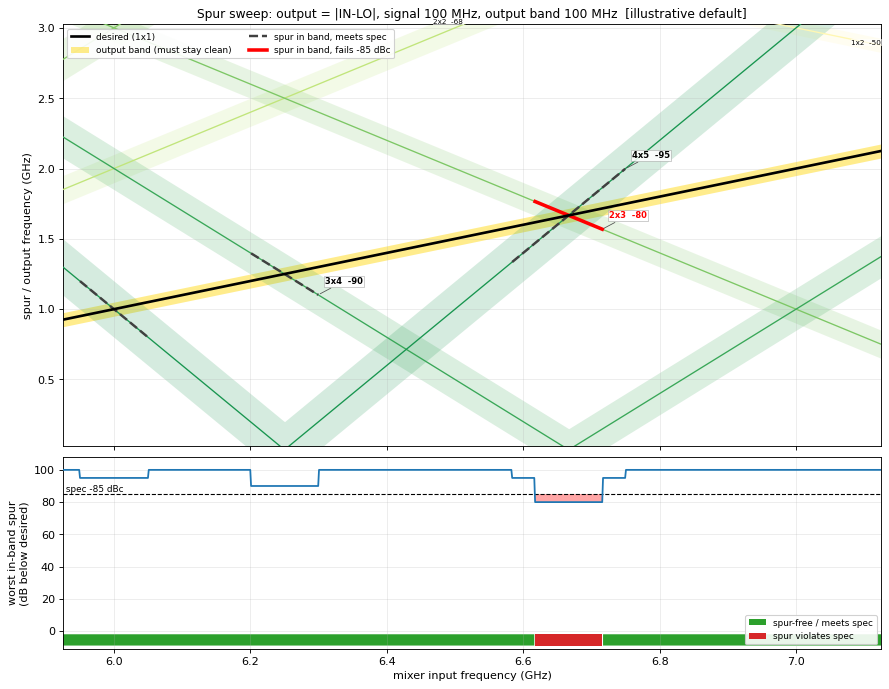

In [81]:
plot_spur_sweep(sw);

**Reading the swept spur view.**

*Top panel: spur frequency against the swept input.* Every mixing product is a line, coloured by
its suppression (red = strong, green = weak); the shaded width around each line is the product's
modulation bandwidth, which grows with `m`. The **thick black line is the desired product** and
the **gold ribbon around it is the output band that must stay clean**. Wherever a spur line
crosses the ribbon it is overdrawn and labelled `mxn -level`: dashed grey if it meets your spec,
**bold red if it violates it** (here the 2×3 product near 6.67 GHz).

*Bottom panel: the verdict.* The blue curve is the worst in-band spur at each input frequency
(100 dB when nothing is in band). The dashed line is your spec. Wherever the curve dips below the
spec the region is shaded red, and the strip along the bottom summarises it: **green = usable
input frequencies, red = unusable**. `spur_free_ranges` returns the green ranges as numbers.

*Two details.* By default an in-band spur is judged at its **full table level**, however little of
it overlaps the band (conservative). Pass `use_overlap_fraction=True` to judge it by the power that
actually lands in the band instead. And the sweep is resampled to at least 1001 points so a spur
crossing between two coarse grid points is not missed.

In [ ]:
loose = rx.spur_sweeps(
    signal_bw=100 * ureg.MHz, max_order=9, spec_dbc=82, use_overlap_fraction=True
)["MX1"]
print(
    "Same signal, -82 dBc spec, judged by power in band:",
    len(spur_free_ranges(loose)),
    "usable range(s)",
)

Same signal, -82 dBc spec, judged by power in band: 1 usable range(s)


## 5. The classic spur chart

The textbook view: **x = input frequency, y = output frequency**, one line per product
`|m·x ± n·LO|`. It is most useful for seeing the *geometry* of a plan at one LO.

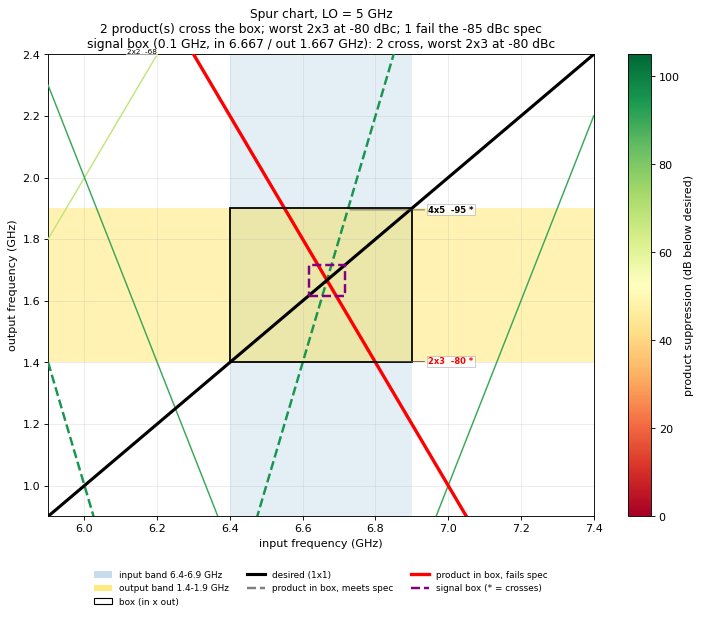

In [ ]:
plot_spur_chart(
    table,
    5.0 * ureg.GHz,
    in_range=(6.4 * ureg.GHz, 6.9 * ureg.GHz),
    signal_bw=100 * ureg.MHz,
    signal_center=6.667 * ureg.GHz,
    spec_dbc=85,
    max_order=9,
);

**Reading the spur chart.** Each line is one mixing product, coloured by suppression. The
**blue vertical strip is your input range** and the **gold horizontal strip is your output
range**; their intersection (black outline) is the **box**. The thick black line is the desired
1×1 product and runs corner to corner through the box.

**A product line passing through the box is an in-band spur**: for some input in your range it
lands in your output range, so no filter can remove it. Those lines are dashed (meets
`spec_dbc`) or bold red (fails) and are labelled beside the box. The purple dashed rectangle is
the **signal box** for a signal of width `signal_bw` at `signal_center`; products crossing it are
marked `*` and are the ones that hit the signal itself at that position. If no line crosses the
box, nothing in the table lands in your band at this LO.

## 6. LO planning for wide converters

`xcvr.loplan` answers the planning questions: **which LO frequencies leave the output passband
spur-free, how far is the nearest spur that needs filtering (the *guard band*), and how much
rejection must the filter give?**

A `Converter` describes the band the hardware must pass (`if_lo`–`if_hi`), the instantaneous signal
inside it, the sideband, and the spec. Here is the transmit side of the same plan: the L-band IF
(0.925–2.125 GHz) up-converted to the 6 GHz band with a 100 MHz signal. `rf_window` limits where the
RF band may land; allowing 100 MHz of slack either side lets the LO tune 4.9–5.1 GHz.

In [ ]:
up = Converter(
    "L-band->6 GHz up",
    0.925 * ureg.GHz,
    2.125 * ureg.GHz,
    direction="up",
    sideband="upper",
    spec_dbc=60,
    signal_bw=100 * ureg.MHz,
    rf_window=(5.825 * ureg.GHz, 7.225 * ureg.GHz),
    table=table,
)
lo_sweep = sweep_lo(up, np.arange(4.5, 5.5, 0.001) * ureg.GHz)
best_los(lo_sweep);

Valid LO windows for L-band->6 GHz up:
           LO window (GHz)    best LO  guard (GHz)  max rej (dB)
          4.9 - 5.099           5.099        0.849          60.0


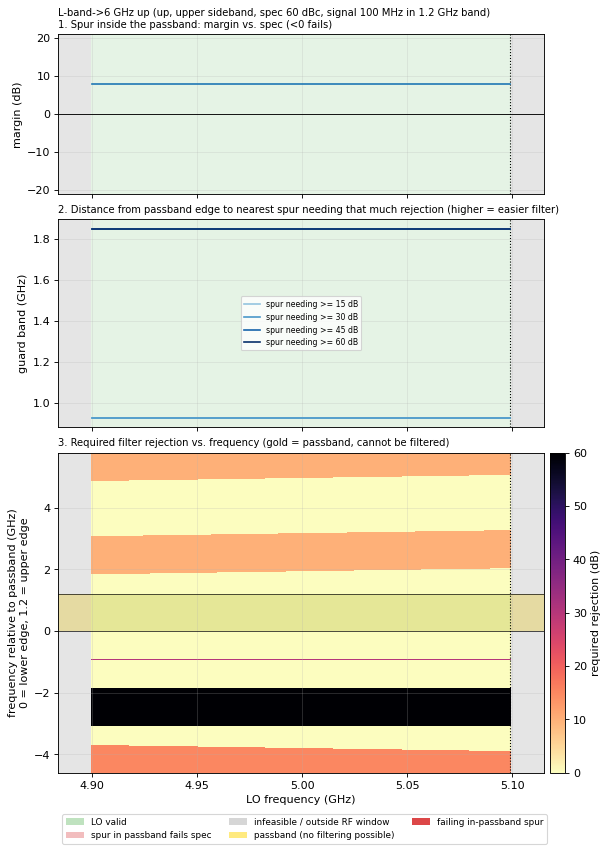

In [85]:
plot_lo_sweep(lo_sweep);

First, the sweep inside this narrow `rf_window`. It is flat, and that is expected (see the end of this
section). **Reading the LO sweep** (three aligned rows, one column per converter). The background is green
where the LO is valid, red where an in-passband spur violates the spec, and grey where the LO is
infeasible or puts the RF band outside `rf_window`. The dotted line marks the best LO.

1. **Margin.** Margin of the worst spur *inside the passband* against its spec. Below 0 dB means
   a spur you cannot filter violates the spec, so avoid that LO.
2. **Guard band.** One line per rejection level: the distance from your band edge to the nearest
   spur that needs at least that much filter rejection. Higher lines mean an easier filter. If the
   60 dB line is low, you need a very steep filter.
3. **Required rejection against frequency, for every LO.** The vertical axis is frequency relative
   to the passband: the **gold strip is the passband at its true width**, where nothing can be
   filtered. Colour outside the strip is the rejection required at that frequency; red inside the
   strip marks a failing in-passband spur.

Inside a narrow `rf_window` the result is often flat. That is physical: when the LO is much larger
than the IF, spurs sit at fixed offsets from the band and slide with it. So run once *without*
`rf_window` over a wide range to see the overall structure:

Valid LO windows for L-band->RF up (no RF window):
           LO window (GHz)    best LO  guard (GHz)  max rej (dB)
         4.25 - 15.99            8.02        0.925          60.0
          1.5 - 1.84             1.52         0.32          60.0


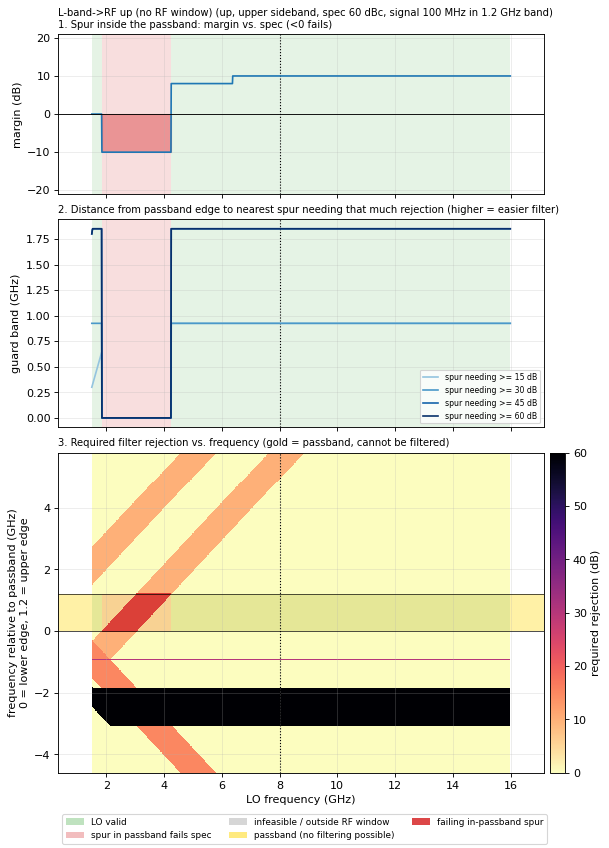

In [ ]:
wide = Converter(
    "L-band->RF up (no RF window)",
    0.925 * ureg.GHz,
    2.125 * ureg.GHz,
    direction="up",
    sideband="upper",
    spec_dbc=60,
    signal_bw=100 * ureg.MHz,
    table=table,
)
wide_sweep = sweep_lo(wide, np.arange(1.5, 16, 0.01) * ureg.GHz)
best_los(wide_sweep)
plot_lo_sweep(wide_sweep);

Now there is structure. Where the **margin (top row) drops below 0 dB** and the background turns
**red**, a spur lands *inside* the passband and violates the spec at that LO. No filter can fix that,
so those LOs are excluded. Here that is an LO of roughly 1.9–4.2 GHz, where the RF band lands on its
own spurs; above that the spurs move away from the band. `best_los` summarises the green windows: the LO range, the best LO in it,
its guard band, and the largest rejection a filter would need. Use the windowed sweep above to
check the LOs your RF window actually allows.

In [87]:
an = analyze(up, 5.0 * ureg.GHz)
filter_report(an)

[L-band->6 GHz up] up-conversion, LO = 5 GHz
  IF band 0.925 GHz-2.125 GHz (1.2 GHz wide, signal 100 MHz)   RF band 5.925 GHz-7.125 GHz
  output passband 5.925 GHz-7.125 GHz   spec 60 dBc
  product       order           spur band (GHz)        where   gap (GHz)   level     need
  |1IN - 2LO|       3       7.875-9.075                above        0.75   -50.0   10.0 dB
  |0IN + 1LO|       1           5-5                    below       0.925   -30.0   30.0 dB
  |1IN - 1LO|       2       2.875-4.075                below        1.85     0.0   60.0 dB
  |1IN + 0LO|       1       0.925-2.125                below         3.8   -45.0   15.0 dB
  |1IN + 2LO|       3       10.93-12.12                above         3.8   -50.0   10.0 dB


**Reading the filter report** (the 5.0 GHz LO is the shared Rx/Tx LO of this plan). `gap` is the distance from the **passband edge** to the nearest
edge of the spur band: your filter must reach `need` dB of rejection by that offset and stay flat
across the passband. The `|1IN - 1LO|` line is the **image** (the unwanted sideband), usually the
main filter driver: here it sits 1.85 GHz below the passband and needs the full 60 dB, because a plain
mixer generates both sidebands. `|0IN + 1LO|` is LO leakage, only 0.925 GHz below the band. Rows marked `IN-CHANNEL` or `IN-PASSBAND` cannot be
filtered at all: change the LO, sideband or IF. An image-reject mixer reduces the image requirement
by `image_rejection_db`.

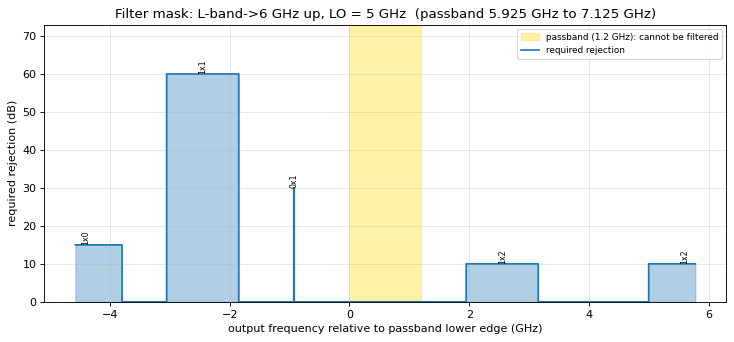

In [88]:
plot_filter_mask(an);

**Reading the filter mask.** Required filter rejection against output frequency at this one LO. The
**gold strip is the passband** (its true width), where nothing can be filtered. The **blue steps are
the rejection required outside it**, labelled with the product that causes each (`mxn`). Red hatched
bars, if any, are spurs landing *inside* the passband, with height equal to the shortfall against the
spec. This is the specification you hand to a filter designer.

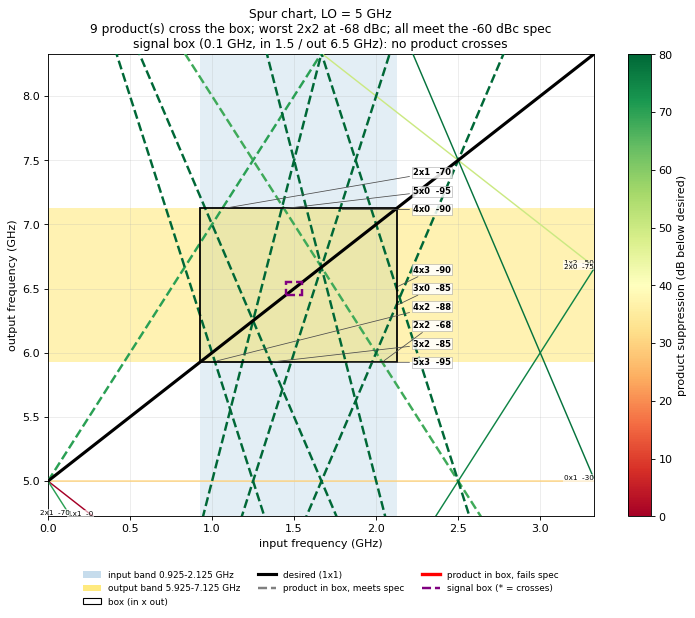

In [89]:
plot_spur_map(up, 5.0 * ureg.GHz, signal_center=1.5 * ureg.GHz);

**The spur map** is the classic chart (section 5) drawn from a `Converter` at a chosen LO, using the
converter's band, spec and table. Use it on the LOs that `best_los` shortlists to see *why* a given
LO is clean.

## 7. Spectrum sweep at a node: absolute spur power through the whole chain

Sections 3–6 give spur levels relative to the desired signal (dBc) at one mixer. To see **absolute
power in dBm at any point in a multi-device chain**, including the effect of filters and gain on
each spur, trace tones through the whole system: `System.trace_tones`.

A swept CW source goes in. Every mixing product is followed: each device applies its own S21 at the
product's *actual* frequency (so filters reject spurs and amplifiers boost them) and each mixer with a
`spur_table` splits every incoming tone into its m×n products.

The chain below has real filter responses. Here they are synthetic band-pass filters standing in for
measured `.s2p` files.

In [ ]:
def bandpass(name, f0, bw, il=1.0, order=3):
    """Synthetic band-pass (stand-in for a measured .s2p): -il dB in band, steep skirts, -90 dB floor."""
    f = np.linspace(1e5, 60e9, 1500)
    g = np.maximum(-il - 3.0 * (np.abs(f - f0) / (bw / 2)) ** (2 * order), -90)
    s = np.zeros((f.size, 2, 2), complex)
    s[:, 1, 0] = s[:, 0, 1] = 10 ** (g / 20)
    net = skrf.Network(frequency=skrf.Frequency.from_f(f, unit="hz"), s=s)
    return Device(name, "Synthetic", "BPF", net, nf=ureg.Quantity(il, "dB"))


# The amplifiers and mixer are datasheet constants. We *declare* them flat over 0.1 MHz-60 GHz, which
# covers every frequency this sweep produces, so no tone falls outside a device's data (section 8).
kw = np.linspace(1e5, 60e9, 241)
kwide = xr.DataArray(kw * ureg.Hz, dims=("frequency",), coords={"frequency": kw})
rx6 = System(
    "RX6",
    "Generic",
    "002",
    [
        Constant("LNA", "G", "L", frequency=kwide, gain=25 * ureg.dB, nf=1 * ureg.dB),  # device 1
        bandpass("RFBPF", 6.525e9, 1.4e9),  # device 2
        MixerConstant(
            "MX1",
            "G",
            "M",
            frequency=kwide,
            gain=-8 * ureg.dB,
            nf=8 * ureg.dB,  # device 3
            lo_freq=5.0 * ureg.GHz,
            sideband="low",
            spur_table=table,
        ),
        bandpass("IFBPF", 1.525e9, 1.4e9, order=4),  # device 4
        Constant("IFA", "G", "I", frequency=kwide, gain=30 * ureg.dB, nf=3 * ureg.dB),  # device 5
    ],
)

# Sweep a -40 dBm tone far beyond the band so out-of-band products are visible too
trace = rx6.trace_tones(ToneSource(np.linspace(1e9, 20e9, 801), -40 * ureg.dBm, "RF"), max_order=9)
trace.node_names  # node 0 = input; node k = output of device k

['input', 'LNA', 'RFBPF', 'MX1', 'IFBPF', 'IFA']

**Nodes.** Node 0 is the system input and node *k* is the output of the *k*-th device. Node 3 is
straight out of the mixer; node 5 is the system output.

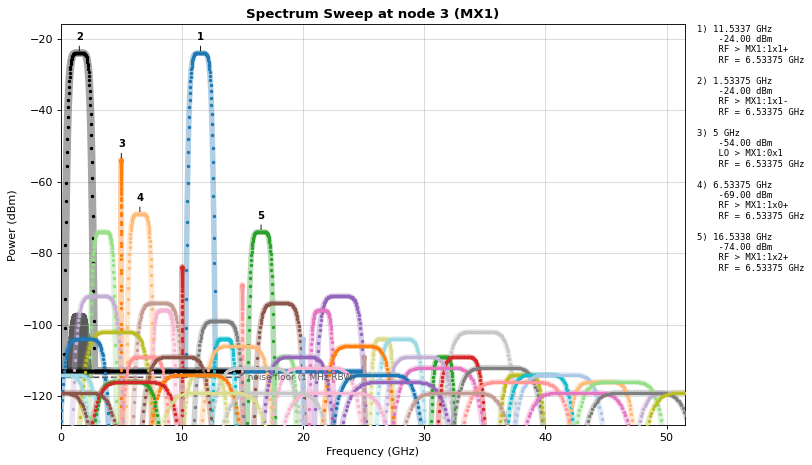

In [91]:
plot_spectrum_sweep(trace.dataset(3));

**Reading the spectrum sweep (node 3, mixer output).** The x-axis is *output frequency* and the
y-axis is *power in dBm*. **Each arch is one mixing path as the source sweeps.** As the input tone
moves, the product's frequency moves with it, and its height follows the chain's gain and filtering
at that point. The arch shape here is the **RF filter's passband**: the tone only reaches the mixer
at full power while it is inside that filter.

* The **black arch** is the desired signal (down-conversion, |IN − LO|).
* Coloured arches are spurs. A path is named by its source and the product at each mixer, e.g.
  `RF > MX1:2x3-` is a 2·IN − 3·LO product. `LO > MX1:0x1` is the LO leaking through.
* The **numbered markers** label the strongest traces, and the list at the right gives each one's
  output frequency, peak power, path, and the *source* frequency at that peak, so you can see which
  input causes it.
* The image product (`MX1:1x1+`) is as strong as the desired one here, because a plain mixer
  generates both sidebands. It sits at a very different frequency, which is why the IF filter exists.

In an interactive backend (`%matplotlib widget`, needs `ipympl`) moving the mouse over a point shows
a tooltip with the same path, frequency, power and sweep frequency.

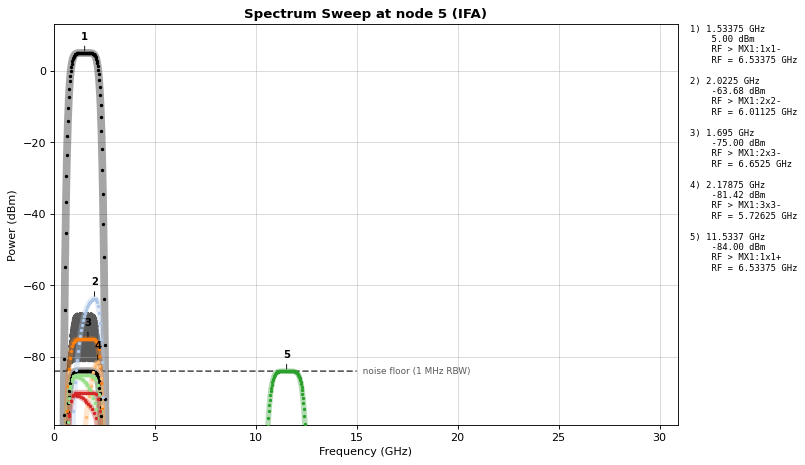

In [92]:
plot_spectrum_sweep(trace.dataset(5));

**Reading the output spectrum (node 5).** Same chain after the IF filter and IF amp. The desired signal is
now amplified (+5 dBm = −40 dBm in, +25 dB LNA, −1 dB RF filter, −8 dB mixer, −1 dB IF filter,
+30 dB IF amp). The image, now near 11.5 GHz, has dropped from −24 dBm to −84 dBm: the synthetic IF filter's
90 dB floor, less the 30 dB the IF amp adds back. The remaining visible spurs are the ones the
filters could not remove: those that land inside the IF passband (the 2×2, 2×3 and 3×3 products). **Compare nodes to see what each device buys you.**

In [93]:
trace.summary(node=5, n=8)

,path,desired,f_min_Hz,f_max_Hz,peak_dBm,f_at_peak_Hz,sweep_at_peak_Hz,extrapolated_in,extrapolated_pct
0,RF > MX1:1x1-,True,1.000000e+07,1.500000e+10,5.000000,1.533750e+09,6.533750e+09,,0.0
1,RF > MX1:2x2-,False,2.000000e+07,3.000000e+10,-63.678808,2.022500e+09,6.011250e+09,,0.0
2,RF > MX1:2x3-,False,1.500000e+07,2.500000e+10,-75.000195,1.695000e+09,6.652500e+09,,0.0
3,RF > MX1:3x3-,False,3.000000e+07,4.500000e+10,-81.416976,2.178750e+09,5.726250e+09,,0.0
4,RF > MX1:1x1+,False,6.000000e+09,2.500000e+10,-84.000000,1.153375e+10,6.533750e+09,,0.0
5,RF > MX1:3x4-,False,2.875000e+07,4.000000e+10,-85.013350,1.253750e+09,6.248750e+09,,0.0
6,RF > MX1:4x5-,False,5.000000e+06,5.500000e+10,-90.000009,1.420000e+09,6.605000e+09,,0.0
7,RF > MX1:1x2-,False,1.250000e+06,1.000000e+10,-102.052040,2.421250e+09,7.578750e+09,,0.0


`summary` tabulates the strongest paths at a node: the frequency span each covers over the sweep, its
peak power, and the output and source frequencies at that peak. `trace.dataset(node)` returns the same
data as an `xarray.Dataset` (`freq` and `power_dbm`, dims `sweep × tone`) for your own analysis.

**What this model does not do.** It is linear: no compression, amplifier harmonics or intermodulation
between tones. Spurs come only from mixers that have a `spur_table`. LO harmonics are generated once per
mixer. Mixer gain is looked up at the frequency the signal entered the system, as in xcvr's cascaded
analysis, so the desired path reproduces `System.gain` and `cascaded_gain` exactly. Set `spur_ref_power`
on a mixer (the input power its table was measured at) to make higher-order products track drive level.
Section 8 shows the checks that tell you when those limits are affecting a result.

## 8. Can I trust this trace? Four built-in checks

The tracer is linear and works from the data you give it, so it also reports when a result leans on
something it cannot know. Each check is a property of the trace, so you can read it or test it in code.

**(a) The noise floor.** The dashed grey line on the spectrum plots in section 7 is the cascaded noise of the
*desired path*: kT at the source plus the noise figure and gain of every device up to that node (Friis),
integrated over a resolution bandwidth (`rbw=`, default 1 MHz). It follows the desired signal's
frequency, so it rides along the black arch. A spur sitting *below* it is buried in the channel's own
noise and rarely matters; a spur *above* it is a real contributor. Compare it with the previous plot:
the amplifiers raise the floor from node to node just as they raise the signal. It agrees with
`System.nf` and `System.gain` (this is tested).

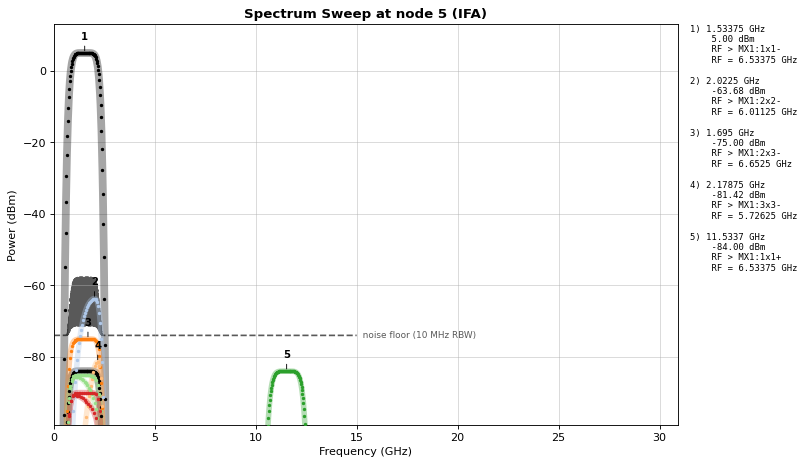

In [ ]:
plot_spectrum_sweep(trace.dataset(5), rbw=10 * ureg.MHz);  # same node, noise integrated over 10 MHz

**(b) Data coverage.** A device's S-parameters only cover the frequencies you measured or defined. A tone
outside that range gets the *edge value*, which is a guess, not data. Such points are drawn as **hollow
markers**, and the side list and tooltip name the devices. They are also in the dataset
(`extrapolated`, `extrap_devices`) and in `summary()`, which gives the devices involved and the
percentage of sweep points affected. `trace_tones` also raises a `UserWarning` when significant output
traces are affected. The chain in section 7 never triggers it, because we declared its amplifiers and
mixer flat over 0.1 MHz-60 GHz, wider than anything the sweep produces. That is an *assumption you
state*, which is the honest way to cover a range you have no data for. Below, the same chain is
defined only over the 6 GHz band (LNA, mixer) and the L-band (IF amplifier), as a datasheet table
would give it, and swept over 1-20 GHz. The desired path is flagged wherever the sweep leaves the
band (the arch's skirts are hollow) and most spurs are flagged somewhere. The in-band part of each
arch is data; the rest is a guess.

In [ ]:
kg = np.linspace(5.925e9, 7.125e9, 41)  # 6 GHz band input
kf = xr.DataArray(kg * ureg.Hz, dims=("frequency",), coords={"frequency": kg})
ig = np.linspace(0.925e9, 2.125e9, 41)  # L-band IF, for the IF amplifier
kif = xr.DataArray(ig * ureg.Hz, dims=("frequency",), coords={"frequency": ig})
rx6_band = System(
    "RX6band",
    "Generic",
    "004",
    [
        Constant("LNA", "G", "L", frequency=kf, gain=25 * ureg.dB, nf=1 * ureg.dB),
        bandpass("RFBPF", 6.525e9, 1.4e9),
        MixerConstant(
            "MX1",
            "G",
            "M",
            frequency=kf,
            gain=-8 * ureg.dB,
            nf=8 * ureg.dB,
            lo_freq=5.0 * ureg.GHz,
            sideband="low",
            spur_table=table,
        ),
        bandpass("IFBPF", 1.525e9, 1.4e9, order=4),
        Constant("IFA", "G", "I", frequency=kif, gain=30 * ureg.dB, nf=3 * ureg.dB),
    ],
)
band_trace = rx6_band.trace_tones(
    ToneSource(np.linspace(1e9, 20e9, 801), -40 * ureg.dBm, "RF"), max_order=9, warn=False
)  # warn=False: we read the table instead
band_trace.summary(node=5, n=6)[["path", "peak_dBm", "extrapolated_in", "extrapolated_pct"]]

,path,peak_dBm,extrapolated_in,extrapolated_pct
0,RF > MX1:1x1-,5.000000,"LNA, MX1, IFA",93.757803
1,RF > MX1:2x2-,-63.678808,"LNA, MX1, IFA",99.250936
2,RF > MX1:2x3-,-75.000195,"LNA, MX1, IFA",96.754057
3,RF > MX1:3x3-,-81.416976,"LNA, MX1, IFA",100.000000
4,RF > MX1:1x1+,-84.000000,"LNA, MX1, IFA",100.000000
5,RF > MX1:3x4-,-85.013350,"LNA, MX1, IFA",97.128589


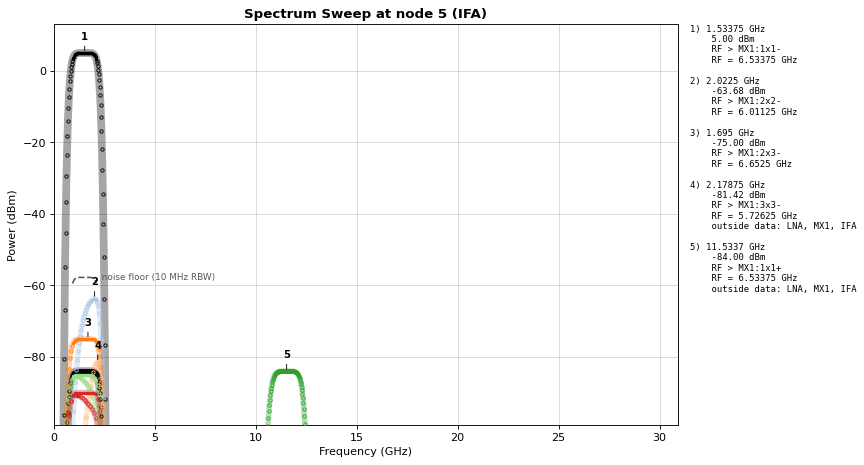

In [ ]:
plot_spectrum_sweep(
    band_trace.dataset(5), rbw=10 * ureg.MHz
);  # hollow markers = outside a device's data

**(c) Pruning.** `max_order`, `min_power_dbm` and `max_tones` keep the trace tractable by dropping
products. `trace.pruning` says how many each device lost and the strongest level dropped. `significant`
is `True` when a dropped trace was within 70 dB of the strongest at that node, which is when you should
raise the limits. Here the order cap (9) removes only two products, at -122 dBm, and the IF filter's 90 dB floor sends
most of the rest below the -150 dBm power floor (`dropped_floor`). Nothing significant was lost.

In [97]:
trace.pruning

,node,device,kept,dropped_order,dropped_floor,dropped_cap,strongest_dropped_dbm,significant
0,1,LNA,1,0,0,0,-inf,False
1,2,RFBPF,1,0,0,0,-inf,False
2,3,MX1,58,2,0,0,-122.0,False
3,4,IFBPF,10,0,48,0,-inf,False
4,5,IFA,10,0,0,0,-inf,False


**(d) Compression.** Compression is flagged but not modelled. After each device the total power is
compared with that device's output P1dB (read at the frequency of the strongest tone); a device whose
margin is negative is `flagged`. The chain above has no P1dB data, so nothing is flagged (`margin_db`
is infinite). Below, the LNA gets a 0 dBm P1dB and the IF amplifier +10 dBm, and the input is raised to
-10 dBm. The LNA output reaches +15 dBm, 15 dB over its P1dB, and the IF amplifier is 25 dB over its own P1dB, so every spur level downstream is
optimistic and the tracer says so.

In [ ]:
hot = System(
    "RX6hot",
    "Generic",
    "003",
    [
        Constant(
            "LNA", "G", "L", frequency=kwide, gain=25 * ureg.dB, nf=1 * ureg.dB, p1db=0 * ureg.dBm
        ),
        bandpass("RFBPF", 6.525e9, 1.4e9),
        MixerConstant(
            "MX1",
            "G",
            "M",
            frequency=kwide,
            gain=-8 * ureg.dB,
            nf=8 * ureg.dB,
            lo_freq=5.0 * ureg.GHz,
            sideband="low",
            spur_table=table,
        ),
        bandpass("IFBPF", 1.525e9, 1.4e9, order=4),
        Constant(
            "IFA", "G", "I", frequency=kwide, gain=30 * ureg.dB, nf=3 * ureg.dB, p1db=10 * ureg.dBm
        ),
    ],
)
hot_trace = hot.trace_tones(
    ToneSource(np.linspace(5.925e9, 7.125e9, 41), -10 * ureg.dBm, "RF"), max_order=9, warn=False
)  # read the table; warn=True also prints a summary
hot_trace.compression

,node,device,max_out_dbm,p1db_dbm,margin_db,sweep_hz,flagged
0,1,LNA,15.000000,0.0,-15.0,5.925000e+09,True
1,2,RFBPF,12.808581,inf,inf,5.925000e+09,False
2,3,MX1,7.821169,inf,inf,5.925000e+09,False
3,4,IFBPF,2.925106,inf,inf,5.925000e+09,False
4,5,IFA,35.000000,10.0,-25.0,6.525000e+09,True


The flags are always in the results (`trace.pruning`, `trace.compression`, the `extrapolated` variable).
By default `trace_tones` also prints a one-time `UserWarning` summarising them; this notebook passes
`warn=False` where it reads the tables itself, so you can see the checks without the noise.